# 03 · Trip statistics

**Who Gets a Bluebike?** · CP 101 final project

Load one month of raw Bluebikes trips and measure how far each ride went in a straight line. This notebook uses January 2024 (`data/raw/bluebikes/202401-bluebikes-tripdata.csv`). Run `00_download_trips.ipynb` first so that file exists.

The distance is the straight line between the recorded start and end points, not the path the rider took. Points start as latitude and longitude (EPSG:4326) and are projected to CRS 2249, the same projected coordinate system as notebook 02 (NAD83 / Massachusetts Mainland, in feet). The distance column is that length in feet.

`trips` is only a runtime variable. It is not written to disk. Each row keeps the trip id, the start and end time, the start and end location, and the distance.

In [1]:
from pathlib import Path

import geopandas as gpd
import pandas as pd
import numpy as np

RAW_TRIPS = Path("../data/raw/bluebikes")
LOCAL_CRS = 2249  # NAD83 / Massachusetts Mainland, in feet

def month_trip_distance(file_name, month_name='month'):
    month = pd.read_csv(
        RAW_TRIPS / file_name,
        usecols=["ride_id", "started_at", "ended_at", "start_lat", "start_lng", "end_lat", "end_lng"],
    )
    month["started_at"] = pd.to_datetime(month["started_at"])
    month["ended_at"] = pd.to_datetime(month["ended_at"])

    # A trip with no end point has no end location and no distance.
    rows_in = len(month)
    month = month.dropna(subset=["start_lat", "start_lng", "end_lat", "end_lng"]).copy()
    print(f"kept {len(month)} of {rows_in} {month_name} trips")

    # lat/lon are degrees (EPSG:4326). Project both ends, then measure the straight line.
    start_points = gpd.GeoSeries(
        gpd.points_from_xy(month["start_lng"], month["start_lat"]),
        crs=4326,
    ).to_crs(LOCAL_CRS)
    end_points = gpd.GeoSeries(
        gpd.points_from_xy(month["end_lng"], month["end_lat"]),
        crs=4326,
    ).to_crs(LOCAL_CRS)
    # Assign by position. The point series has its own index, so label alignment would leave gaps.
    month["distance"] = start_points.distance(end_points).to_numpy()

    # Temporary working table: trip id, times, locations, and distance. Not saved.
    trips = month[
        ["ride_id", "started_at", "ended_at", "start_lat", "start_lng", "end_lat", "end_lng", "distance"]
    ].copy()
    trips['distance_miles'] = trips['distance'] / 5280
    greater_than_zero_distance = trips[trips['distance'] > 0]
    return greater_than_zero_distance


In [2]:
files = ["202401-bluebikes-tripdata.csv",
         "202402-bluebikes-tripdata.csv",
         "202403-bluebikes-tripdata.csv",
         "202404-bluebikes-tripdata.csv",
         "202405-bluebikes-tripdata.csv",
         "202406-bluebikes-tripdata.csv",
         "202407-bluebikes-tripdata.csv",
         "202408-bluebikes-tripdata.csv",
         "202409-bluebikes-tripdata.csv",
         "202410-bluebikes-tripdata.csv",
         "202411-bluebikes-tripdata.csv",
         "202412-bluebikes-tripdata.csv"]
months = ['January',
          'February',
          'March',
          'April',
          'May',
          'June',
          'July',
          'August',
          'September',
          'October',
          'November',
          'December']

counts = pd.Series(0, index=range(9))
for i in range(12):
    miles = month_trip_distance(files[i], months[i])['distance_miles']
    half_mile = np.floor(miles.to_numpy() * 2).astype(int)
    half_mile = np.clip(half_mile, 0, 8)
    labels = ["0-0.5", "0.5-1", "1-1.5", "1.5-2", "2-2.5", "2.5-3", "3-3.5", "3.5-4", ">4"]
    counts += pd.Series(half_mile).value_counts().reindex(range(len(labels)), fill_value=0)

percents = counts / counts.sum() * 100
    

kept 166586 of 166699 January trips
kept 231781 of 231947 February trips
kept 261487 of 261687 March trips
kept 356059 of 356327 April trips
kept 440194 of 440534 May trips
kept 478371 of 478860 June trips
kept 542115 of 542622 July trips
kept 537860 of 538262 August trips
kept 582284 of 582679 September trips
kept 563843 of 564156 October trips
kept 397204 of 397406 November trips
kept 190499 of 190611 December trips


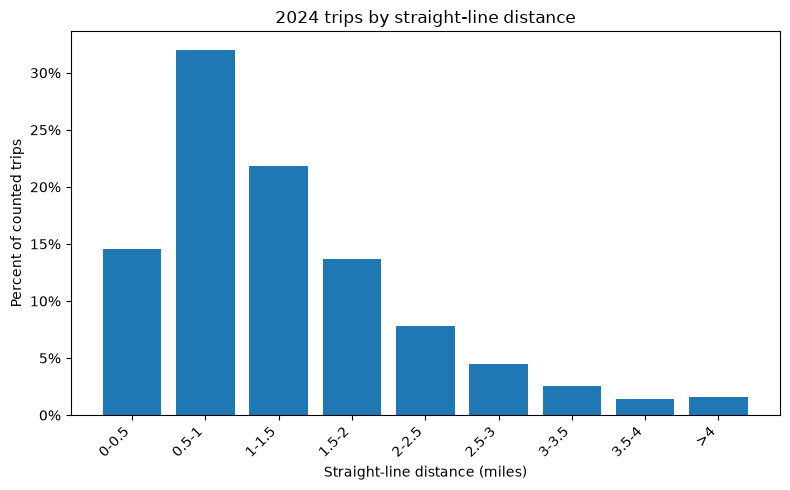

In [4]:
import matplotlib.pyplot as plt
import numpy as np

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(labels, percents.to_numpy())
ax.set_xlabel("Straight-line distance (miles)")
ax.set_ylabel("Percent of counted trips")
ax.set_title("2024 trips by straight-line distance")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _pos: f"{value:.0f}%"))
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()